# Disponibilité moyenne par heure de la journée — semaine vs week-end

**Objectif** : observer comment le nombre moyen de vélos disponibles évolue
au fil de la journée, et si ce profil diffère entre jours de semaine et
week-end.

**Méthode** : agrégation par heure locale (Europe/Paris) et type de jour
via la vue SQL `v_hourly_availability` (voir
`database/migrations/003_analysis_views.sql`).

**Couverture** : ce notebook commence par un contrôle de couverture des
données. Au-delà de notre propre collecte en direct (`source = 'live'`),
`station_status` inclut un mois d'historique réel importé depuis
l'archive communautaire ODbL `tibzsecondaire/velib-data` (voir le README,
section Attribution) — d'où la profondeur de données disponible ici.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from _common import get_engine

engine = get_engine()

## 1. Contrôle de couverture des données


In [2]:
couverture = pd.read_sql(
    """
    SELECT min(ts) AS debut, max(ts) AS fin, max(ts) - min(ts) AS duree,
           count(*) AS nb_mesures,
           count(DISTINCT date_trunc('hour', ts)) AS nb_heures_distinctes
    FROM station_status
    """,
    engine,
)
print(couverture.to_string(index=False))

jours_type = pd.read_sql(
    """
    SELECT CASE WHEN EXTRACT(ISODOW FROM ts AT TIME ZONE 'Europe/Paris') IN (6,7)
                THEN 'week-end' ELSE 'semaine' END AS jour_type,
           count(DISTINCT (ts AT TIME ZONE 'Europe/Paris')::date) AS nb_jours
    FROM station_status
    GROUP BY 1
    """,
    engine,
)
print(jours_type.to_string(index=False))

                    debut                              fin                   duree  nb_mesures  nb_heures_distinctes
2026-10-05 21:32:08+00:00 2026-11-09 19:40:54.882068+00:00 34 days 22:08:46.882068     8856550                   739
jour_type  nb_jours
  semaine        26
 week-end        10


## 2. Disponibilité moyenne par heure


In [3]:
df = pd.read_sql("SELECT * FROM v_hourly_availability ORDER BY jour_type, heure", engine)
df

    heure jour_type  avg_mecanique  avg_electrique  avg_velos_total  avg_bornes_libres  nb_mesures
0       0   semaine           7.68            5.13            12.81              18.95      306857
1       1   semaine           7.76            5.26            13.02              18.79      282541
2       2   semaine           7.79            5.35            13.15              18.69      215707
3       3   semaine           7.74            5.38            13.12              18.58      249125
4       4   semaine           7.82            5.43            13.25              18.55      265839
5       5   semaine           7.87            5.43            13.29              18.52      246086
6       6   semaine           7.79            5.35            13.14              18.58      258239
7       7   semaine           7.63            5.07            12.70              18.94      243047
8       8   semaine           7.38            4.52            11.90              19.90      198990
9       9 

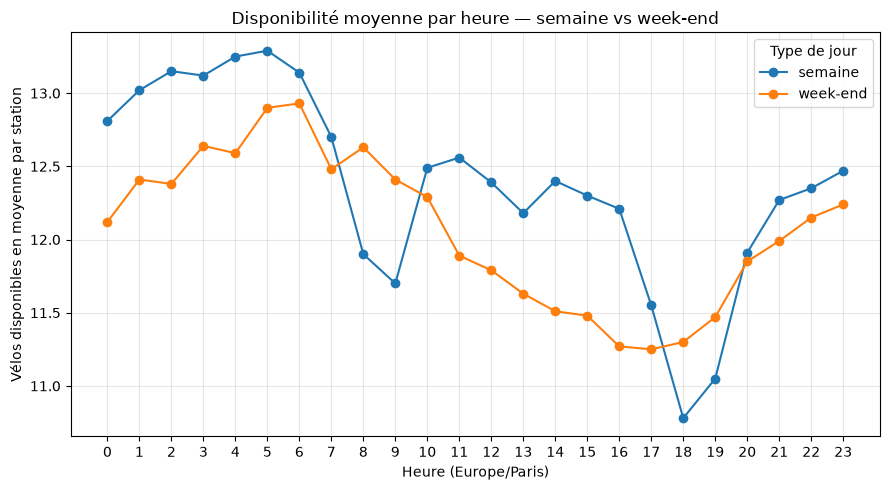

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for jour_type, groupe in df.groupby("jour_type"):
    ax.plot(groupe["heure"], groupe["avg_velos_total"], marker="o", label=jour_type)
ax.set_xlabel("Heure (Europe/Paris)")
ax.set_ylabel("Vélos disponibles en moyenne par station")
ax.set_title("Disponibilité moyenne par heure — semaine vs week-end")
ax.set_xticks(range(0, 24))
ax.legend(title="Type de jour")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion

Avec 35 jours réels (26 jours de semaine, 10 jours de week-end), un vrai
profil quotidien apparaît :

- **En semaine**, la disponibilité suit un profil bimodal typique d'un
  usage domicile-travail : elle culmine la nuit (~13,3 vélos/station vers
  4h-5h), **chute à la pointe du matin** (11,70 vélos vers 9h — les gens
  prennent un vélo pour aller travailler), remonte un peu en journée, puis
  **rechute à la pointe du soir** (10,78 vélos vers 18h — le creux le plus
  marqué de la journée).
- **Le week-end**, le profil est beaucoup plus plat : pas de creux du
  matin (12,63 vélos à 8h, contre 11,90 en semaine), un seul creux large
  l'après-midi (~11,3-11,5 entre 13h et 17h) cohérent avec un usage loisir
  plutôt que commute.

Cette différence de forme entre semaine et week-end est exactement le
signal attendu pour un système de vélos en libre-service, et constitue
une feature temporelle évidente pour le modèle de prédiction (heure +
jour de semaine/week-end).
